# Neural Machine Translation (Chinese → English) with a Seq2Seq + Attention model

A cleaned-up, self-contained version of **CS224N Assignment 4**. It keeps everything you need to understand and build the model, and drops the course plumbing.

**What you'll build:** subword tokenizer → embeddings → 1D CNN → bidirectional LSTM encoder → LSTM decoder with **multiplicative attention** → softmax over English subwords. Trained with teacher forcing, decoded with beam search, scored with BLEU.

| # | Section | Assignment part |
|---|---------|-----------------|
| 1 | Setup & config | — |
| 2 | The big picture | model description |
| 3 | Data | `zh_en_data/` |
| 4 | Subword tokenization (SentencePiece) | `vocab.py`, Q2a hint |
| 5 | Batching & padding | Q1a `pad_sents` |
| 6 | The model, piece by piece | Q1b–Q1g |
| 7 | Sanity checks (shapes, initial loss, overfit one batch) | replaces `sanity_check.py` |
| 8 | Training | `run.py train` |
| 9 | Decoding: greedy & beam search | `beam_search` |
| 10 | Evaluation: BLEU + attention heatmaps | Q1h |
| 11 | Written questions, answered | Q1g, Q1i, Q2a–c |
| 12 | Optional: compare with a modern pretrained model | — |
| 13 | Cheat sheet | — |

### What was simplified (and the modern replacement)

| Original | Here | Why |
|---|---|---|
| `vocab.py` (`VocabEntry`, `Vocab`, JSON) | SentencePiece directly gives ids + `<pad>/<s>/</s>/<unk>` | one less abstraction |
| `utils.pad_sents` | `torch.nn.utils.rnn.pad_sequence` | standard PyTorch |
| `batch_iter` + sorting by length | `DataLoader` + `pack_padded_sequence(enforce_sorted=False)` | no manual sorting |
| `generate_sent_masks` loop | `mask = (src == PAD)` | one line |
| `torch.gather` + target masks | `F.cross_entropy(..., ignore_index=PAD)` | standard loss |
| hand-rolled patience / LR decay | `ReduceLROnPlateau` + reload best checkpoint | standard scheduler |
| sequence-first tensors `(len, b, ·)` | batch-first `(b, len, ·)` | modern convention, easier to read |
| `docopt` CLI, `run.sh/.bat`, Azure VM/tmux, TensorBoard, `sanity_check.py` + pickles, `collect_submission` | removed | not needed to learn NMT |

> ⚠️ Note: in the original data, `train_debug.zh` has **10** lines but `train_debug.en` has **1000**, so the debug pairs are misaligned. Debug mode here uses a slice of the real training set instead.

## 1. Setup

Run on a GPU if you can (Colab / Kaggle T4 is fine). Full training takes roughly 1–2 hours on a GPU; `DEBUG = True` runs a tiny version on CPU in a few minutes so you can check that everything works.

In [1]:
%pip install -q sentencepiece sacrebleu nltk tqdm matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import math, random, time, zipfile
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader

import sentencepiece as spm
import sacrebleu
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_float32_matmul_precision("high")   # allows TF32 on Ampere+ GPUs: free speedup
print("device:", device, "| torch", torch.__version__)

device: cpu | torch 2.14.1


/Users/deepanshu/Documents/NLP_6120/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
@dataclass
class Config:
    # data / tokenizer
    src_vocab_size: int = 21000    # Chinese subword vocab (many characters → bigger vocab)
    tgt_vocab_size: int = 8000     # English subword vocab
    # model  (run.py docopt defaults are 256/256; your edited run.py used 1024/768)
    embed_size: int = 256
    hidden_size: int = 256
    dropout: float = 0.3
    # optimisation  (values from run.sh `train`)
    batch_size: int = 32
    lr: float = 5e-4
    clip_grad: float = 5.0
    uniform_init: float = 0.1      # every parameter ~ U(-0.1, 0.1)
    max_epochs: int = 30
    valid_every: int = 200         # evaluate dev perplexity every N steps
    patience: int = 1              # bad evals before LR decay
    lr_decay: float = 0.5
    max_decays: int = 5            # stop after this many decays ("max_num_trial")
    # decoding
    beam_size: int = 5             # your edited run.py used 10
    max_decode_len: int = 70
    # debug
    debug: bool = False
    debug_train_size: int = 5000

DEBUG = not torch.cuda.is_available()    # flip manually if you like
cfg = Config(debug=DEBUG)
if cfg.debug:
    cfg.max_epochs, cfg.valid_every, cfg.max_decays = 2, 50, 2
cfg

Config(src_vocab_size=21000, tgt_vocab_size=8000, embed_size=256, hidden_size=256, dropout=0.3, batch_size=32, lr=0.0005, clip_grad=5.0, uniform_init=0.1, max_epochs=2, valid_every=50, patience=1, lr_decay=0.5, max_decays=2, beam_size=5, max_decode_len=70, debug=True, debug_train_size=5000)

In [4]:
# Locate the data. Put this notebook in assignment4/code/, or next to assignment4.zip.
DATA_DIR = next((p for p in [Path("zh_en_data"), Path("code/zh_en_data"), Path("assignment4/code/zh_en_data")]
                 if (p / "train.zh").exists()), None)
if DATA_DIR is None and Path("assignment4.zip").exists():
    with zipfile.ZipFile("assignment4.zip") as z:
        z.extractall(".", [m for m in z.namelist() if "zh_en_data/" in m and not m.startswith("__MACOSX")])
    DATA_DIR = Path("assignment4/code/zh_en_data")
assert DATA_DIR is not None, "Couldn't find zh_en_data/ — set DATA_DIR manually."
print("data:", DATA_DIR.resolve())

data: /Users/deepanshu/Documents/NLP_6120/Standford_NLP/assignments/CS224N-main/assignment4/code/zh_en_data


## 2. The big picture

**Machine translation** = model $P(\mathbf{y} \mid \mathbf{x})$, the probability of a target sentence $\mathbf{y}$ (English) given a source sentence $\mathbf{x}$ (Chinese). A seq2seq model factorises it one token at a time:

$$
P(\mathbf{y}\mid\mathbf{x}) = \prod_{t=1}^{T} P(y_t \mid y_{<t}, \mathbf{x})
$$

- **Encoder** reads the whole source sentence and produces one vector per source token.
- **Decoder** generates the target one token at a time, conditioned on what it has produced so far.
- **Attention** lets the decoder, at each step, look back at *all* encoder vectors and pick the relevant ones — instead of squeezing the whole sentence into a single vector (the "bottleneck" problem of plain seq2seq).

The figure from the handout (decoder at step 3, predicting "desserts"):

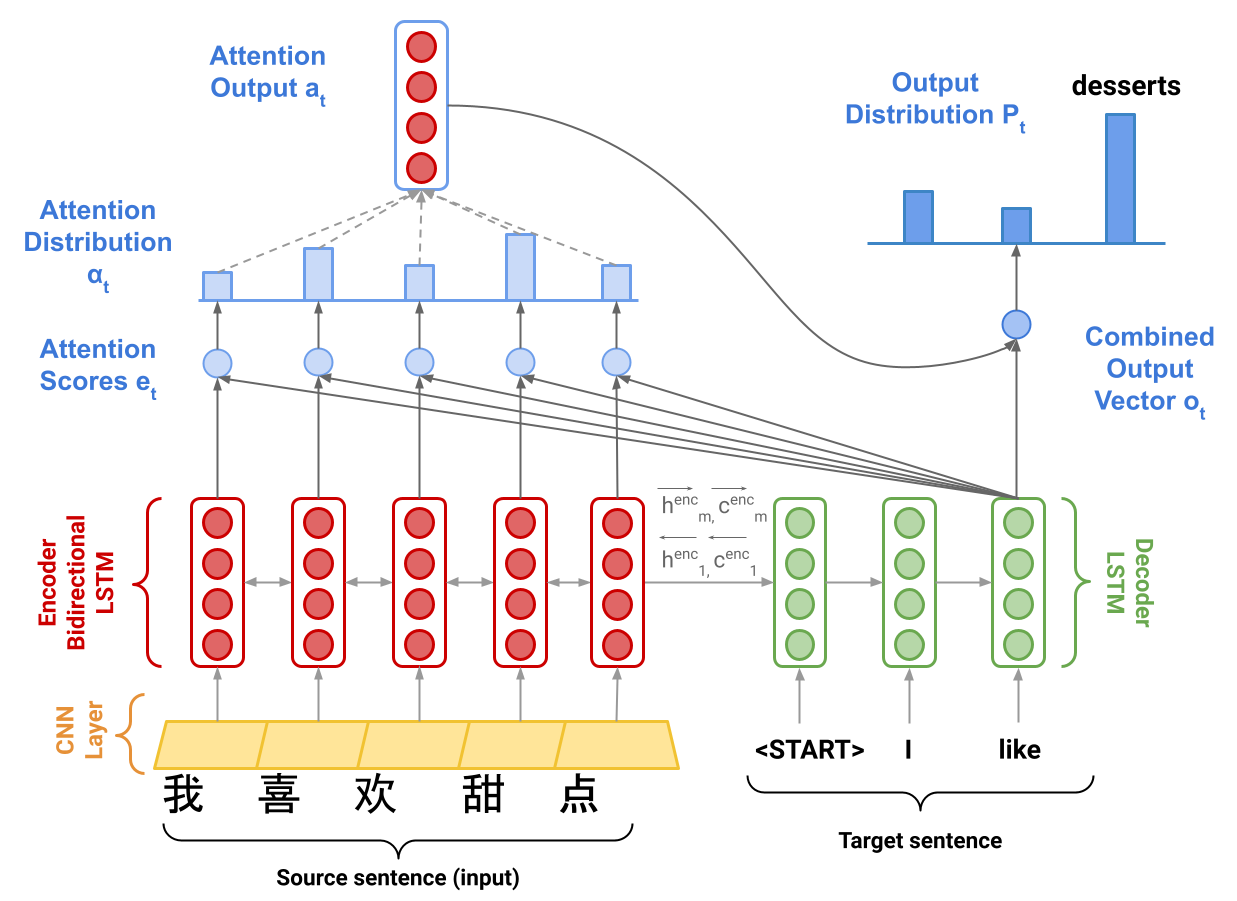

The same thing, with tensor shapes (b = batch, m = source length, T = target length, e = embed size, h = hidden size, V = target vocab):

```
SOURCE  我 喜欢 甜点                            TARGET (teacher forcing)  <s>  I  like
          │  SentencePiece → ids  (b, m)                                     │  ids (b, T)
          ▼                                                                  ▼
   ┌─────────────┐                                                   ┌─────────────┐
   │  Embedding  │  (b, m, e)                                        │  Embedding  │  y_t  (b, e)
   └──────┬──────┘                                                   └──────┬──────┘
          ▼                                                                 ▼
   ┌─────────────┐                                       ȳ_t = [y_t ; o_{t-1}]  (b, e+h)   ◄── input feeding
   │ Conv1d  k=2 │  (b, m, e)   local n-gram features                         ▼
   └──────┬──────┘                                                   ┌─────────────┐
          ▼                                                          │  LSTMCell   │  h_t, c_t  (b, h)
   ┌─────────────┐   final states ──► W_h, W_c ──► (h_0, c_0) ──────►└──────┬──────┘
   │   BiLSTM    │                                                          │
   └──────┬──────┘                                                          ▼
          │ h_enc (b, m, 2h) ────────────────────────────────► ATTENTION:  e_t = h_encᵀ W_att h_t   (b, m)
                                                                           α_t = softmax(e_t)       (b, m)
                                                                           a_t = Σ α_ti h_enc_i     (b, 2h)
                                                                                    ▼
                                                     o_t = dropout(tanh(W_u [a_t ; h_t]))    (b, h)
                                                     P_t = softmax(W_vocab o_t)              (b, V)  → "desserts"
```

## 3. Data

Sentence-aligned Chinese/English news text (GALE Phase 3, LDC2017T02): line *i* of `train.zh` translates line *i* of `train.en`. English is already lower-cased.

| split | pairs |
|---|---|
| train | 200,000 |
| dev | 1,001 (model selection / early stopping) |
| test | 1,001 (final BLEU) |

In [20]:
def read_lines(path):
    with open(path, encoding="utf8") as f:
        return [line.strip() for line in f]

raw = {split: (read_lines(DATA_DIR / f"{split}.zh"), read_lines(DATA_DIR / f"{split}.en"))
       for split in ["train", "dev", "test"]}
for split, (zh, en) in raw.items():
    assert len(zh) == len(en), split
    print(f"{split:5s}: {len(zh):,} pairs")

for i in range(3):
    print("\nZH:", raw["train"][0][i], "\nEN:", raw["train"][1][i])

train: 200,000 pairs
dev  : 1,001 pairs
test : 1,001 pairs

ZH: 事发时身穿白色外衣,深色上衣及深色褲。 
EN: he was seen wearing a white jacket, a dark-coloured t-shirt and pants.

ZH: 香港浸会大学体毓及康乐管理学亦向参加者解释运动与身体状湟的关系。 
EN: they were also briefed by the physical education and recreation management society of hong kong baptist university on the relationship between doing exercises and physical well-being.

ZH: 我力求部门开放透明,让员工可预先知道部门的计划。 
EN: i go for as much transparency as possible so that my staff will know in advance what is being planned for the organisation.


## 4. Subword tokenization with SentencePiece

Neural models need a **fixed vocabulary**. Options:

| unit | problem |
|---|---|
| words | Chinese has **no spaces**, so "words" need a separate segmenter; huge vocab; many unknown words |
| characters | sequences get long; meaning often spans several characters |
| **subwords** ✅ | frequent strings become single tokens, rare words are split into pieces → small vocab, (almost) no `<unk>` |

**SentencePiece** (Google; used by T5, LLaMA, mT5, Marian…) learns subwords straight from raw text, treating the space as an ordinary symbol `▁`. That is why it works on Chinese without any pre-segmentation. We use its default **Unigram LM** algorithm: start from a big candidate vocab and prune pieces whose removal hurts the corpus likelihood least.

We reserve the special ids ourselves, which replaces the whole `vocab.py` file:

| id | token | use |
|---|---|---|
| 0 | `<pad>` | padding |
| 1 | `<unk>` | unknown |
| 2 | `<s>` | start of target |
| 3 | `</s>` | end of target |

In [21]:
PAD, UNK, BOS, EOS = 0, 1, 2, 3

def train_spm(input_file, prefix, vocab_size, character_coverage):
    if not Path(f"{prefix}.model").exists():
        spm.SentencePieceTrainer.train(
            input=str(input_file), model_prefix=prefix, vocab_size=vocab_size,
            model_type="unigram", character_coverage=character_coverage,
            pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS,
            hard_vocab_limit=False)        # don't crash if the corpus can't fill the vocab
    return spm.SentencePieceProcessor(model_file=f"{prefix}.model")

# Always train the tokenizers on the full training set (takes ~1–2 min).
sp_src = train_spm(DATA_DIR / "train.zh", "src", cfg.src_vocab_size, character_coverage=0.9995)  # rare chars → <unk>
sp_tgt = train_spm(DATA_DIR / "train.en", "tgt", cfg.tgt_vocab_size, character_coverage=1.0)
print("src vocab:", sp_src.get_piece_size(), "| tgt vocab:", sp_tgt.get_piece_size())

src vocab: 21000 | tgt vocab: 8000


In [22]:
for s in ["我的电脑坏了。", raw["train"][0][2]]:
    print(s, "→", sp_src.encode(s, out_type=str))
print(sp_tgt.encode("the culprits were subsequently arrested.", out_type=str))
print("电 / 脑 / 电脑 in vocab:", [sp_src.piece_to_id(p) != UNK for p in ["电", "脑", "电脑"]])

我的电脑坏了。 → ['▁我', '的', '电脑', '坏', '了', '。']
我力求部门开放透明,让员工可预先知道部门的计划。 → ['▁我', '力求', '部门', '开放', '透明', ',', '让', '员工', '可', '预先', '知道', '部门的', '计划', '。']
['▁the', '▁culprit', 's', '▁were', '▁subsequently', '▁arrested', '.']
电 / 脑 / 电脑 in vocab: [True, True, True]


Note how multi-character words like 电脑 ("electricity"+"brain" = *computer*) can be one piece or several. When they get split, the model has to **recombine neighbouring pieces** — that's what the CNN in §6.2 is for (Q2a).

## 5. Batching & padding (Q1a)

Tensors must be rectangular, so in each batch we **pad** shorter sentences up to the longest one with `<pad>` (id 0). The original `pad_sents` did this on lists of strings; `pad_sequence` does it on tensors:

```
lengths [5, 3, 2]          src (b=3, m=5)              mask = (src == PAD)
                           ┌─────────────────┐          ┌───────────┐
我 喜欢 吃 甜 点            │ 17  52  9  44 81 │          │ F F F F F │
他 来 了                    │ 23  11  6   0  0 │   →      │ F F F T T │   True = padding
你 好                       │ 99  14  0   0  0 │          │ F F T T T │
                           └─────────────────┘          └───────────┘
```

Targets are wrapped as `<s> … </s>`. Sources aren't (the encoder doesn't need them).

In [23]:
class ParallelDataset(Dataset):
    def __init__(self, src_lines, tgt_lines):
        src = sp_src.encode(src_lines)                                # list[list[int]]
        tgt = sp_tgt.encode(tgt_lines, add_bos=True, add_eos=True)    # <s> ... </s>
        # drop empty lines (an empty sequence would break pack_padded_sequence)
        self.pairs = [(s, t) for s, t in zip(src, tgt) if len(s) > 0 and len(t) > 2]
    def __len__(self):  return len(self.pairs)
    def __getitem__(self, i): return self.pairs[i]

def collate(batch):
    src, tgt = zip(*batch)
    src_lens = torch.tensor([len(s) for s in src])                    # stays on CPU (packing needs it there)
    src = pad_sequence([torch.tensor(s) for s in src], batch_first=True, padding_value=PAD)
    tgt = pad_sequence([torch.tensor(t) for t in tgt], batch_first=True, padding_value=PAD)
    return src, src_lens, tgt

train_zh, train_en = raw["train"]
if cfg.debug:
    train_zh, train_en = train_zh[:cfg.debug_train_size], train_en[:cfg.debug_train_size]

train_ds = ParallelDataset(train_zh, train_en)
dev_ds   = ParallelDataset(*raw["dev"])
train_dl = DataLoader(tra/in_ds, batch_size=cfg.batch_size, shuffle=True, collate_fn=collate)
dev_dl   = DataLoader(dev_ds, batch_size=64, shuffle=False, collate_fn=collate)

src, src_lens, tgt = next(iter(train_dl))
print("src", tuple(src.shape), "| tgt", tuple(tgt.shape), "| src_lens", src_lens[:8].tolist())
print("mask row 0:", (src[0] == PAD).int().tolist())

NameError: name 'tra' is not defined

## 6. The model, piece by piece

Notation ↔ code (column vectors in the maths, batch-first rows in the code):

| symbol | meaning | code | shape |
|---|---|---|---|
| $\mathbf{x}_i$ | source embedding | `src_embed(src)` | (b, m, e) |
| $\mathbf{h}^{enc}_i$ | encoder hidden (fw ⊕ bw) | `enc_h` | (b, m, 2h) |
| $\mathbf{h}^{dec}_t, \mathbf{c}^{dec}_t$ | decoder hidden / cell | `h_t, c_t` | (b, h) |
| $\mathbf{e}_t$ | attention scores | `e_t` | (b, m) |
| $\alpha_t$ | attention distribution | `alpha_t` | (b, m) |
| $\mathbf{a}_t$ | attention output (context) | `a_t` | (b, 2h) |
| $\mathbf{o}_t$ | combined output | `o_t` | (b, h) |
| $\mathbf{P}_t$ | distribution over target vocab | `softmax(logits)` | (b, V) |

### 6.1 Embeddings (Q1b)
A lookup table $\mathbf{E}\in\mathbb{R}^{V\times e}$: token id $k$ → row $k$. One table per language. `padding_idx=PAD` keeps the `<pad>` row at zero and never updates it.

### 6.2 1D convolution over the source (Q2a)
A `Conv1d` with kernel size 2 mixes each piece with its right neighbour; `padding="same"` keeps the length $m$:

$$
\tilde{\mathbf{x}}_i = \mathbf{W}_0\,\mathbf{x}_i + \mathbf{W}_1\,\mathbf{x}_{i+1} + \mathbf{b}
$$

```
pieces:   电    脑    坏    了
           \  /  \  /  \  /  \
conv:     [电脑] [脑坏] [坏了] [了 ·]     each output sees a 2-gram
```

This gives the encoder **bigram features** for free, so pieces like 电 + 脑 can be recognised as one word (*computer*). `Conv1d` expects channels-first, so we transpose `(b, m, e) → (b, e, m)` and back.

### 6.3 Bidirectional LSTM encoder (Q1d)

$$
\overrightarrow{\mathbf{h}}^{enc}_i = \text{LSTM}_{\rightarrow}(\tilde{\mathbf{x}}_i, \overrightarrow{\mathbf{h}}^{enc}_{i-1}),\qquad
\overleftarrow{\mathbf{h}}^{enc}_i = \text{LSTM}_{\leftarrow}(\tilde{\mathbf{x}}_i, \overleftarrow{\mathbf{h}}^{enc}_{i+1})
$$
$$
\mathbf{h}^{enc}_i = [\overleftarrow{\mathbf{h}}^{enc}_i;\ \overrightarrow{\mathbf{h}}^{enc}_i] \in \mathbb{R}^{2h},\qquad
\mathbf{c}^{enc}_i = [\overleftarrow{\mathbf{c}}^{enc}_i;\ \overrightarrow{\mathbf{c}}^{enc}_i] \in \mathbb{R}^{2h}
$$

For reference, one LSTM step ($\sigma$ = sigmoid, $\odot$ = element-wise product):

$$
\begin{aligned}
\mathbf{i},\mathbf{f},\mathbf{o} &= \sigma(\mathbf{W}\mathbf{x}_t + \mathbf{U}\mathbf{h}_{t-1} + \mathbf{b}) &&\text{input / forget / output gates}\\
\tilde{\mathbf{c}}_t &= \tanh(\mathbf{W}_c\mathbf{x}_t + \mathbf{U}_c\mathbf{h}_{t-1} + \mathbf{b}_c) &&\text{candidate memory}\\
\mathbf{c}_t &= \mathbf{f}\odot\mathbf{c}_{t-1} + \mathbf{i}\odot\tilde{\mathbf{c}}_t,\qquad \mathbf{h}_t = \mathbf{o}\odot\tanh(\mathbf{c}_t)
\end{aligned}
$$

**Packing.** `pack_padded_sequence` tells the LSTM each sentence's true length, so it never runs over `<pad>` tokens. Without it, the backward LSTM would *start* on padding, and the "final" states would be computed from garbage. With `enforce_sorted=False`, PyTorch handles sorting internally (the original code sorted every batch by hand).

### 6.4 Initialising the decoder

The **forward** LSTM has read the whole sentence when it reaches position $m$; the **backward** LSTM has read it all when it reaches position 1. So those two states are the natural "sentence summary":

$$
\mathbf{h}^{dec}_0 = \mathbf{W}_h[\overleftarrow{\mathbf{h}}^{enc}_1;\ \overrightarrow{\mathbf{h}}^{enc}_m],\qquad
\mathbf{c}^{dec}_0 = \mathbf{W}_c[\overleftarrow{\mathbf{c}}^{enc}_1;\ \overrightarrow{\mathbf{c}}^{enc}_m],\qquad \mathbf{W}_h,\mathbf{W}_c\in\mathbb{R}^{h\times 2h}
$$

In PyTorch these are exactly `h_n[0]` (forward) and `h_n[1]` (backward), returned by `nn.LSTM`.

### 6.5 One decoder step with multiplicative attention (Q1f)

**Input feeding** (Luong et al., 2015): the decoder input is the current target embedding concatenated with the previous combined output, so the decoder knows what it attended to last step ($\mathbf{o}_0 = \mathbf{0}$):

$$
\bar{\mathbf{y}}_t = [\mathbf{y}_t;\ \mathbf{o}_{t-1}] \in \mathbb{R}^{e+h},\qquad
\mathbf{h}^{dec}_t, \mathbf{c}^{dec}_t = \text{LSTMCell}(\bar{\mathbf{y}}_t,\ \mathbf{h}^{dec}_{t-1}, \mathbf{c}^{dec}_{t-1})
$$

**Attention** — score every source position, normalise, take the weighted average:

$$
\mathbf{e}_{t,i} = (\mathbf{h}^{dec}_t)^\top\,\mathbf{W}_{attProj}\,\mathbf{h}^{enc}_i \quad(\mathbf{W}_{attProj}\in\mathbb{R}^{h\times 2h}),\qquad
\alpha_t = \text{softmax}(\mathbf{e}_t),\qquad
\mathbf{a}_t = \sum_{i=1}^{m}\alpha_{t,i}\,\mathbf{h}^{enc}_i
$$

**Combine & predict:**

$$
\mathbf{u}_t = [\mathbf{a}_t;\ \mathbf{h}^{dec}_t]\in\mathbb{R}^{3h},\quad
\mathbf{o}_t = \text{dropout}(\tanh(\mathbf{W}_u\mathbf{u}_t))\in\mathbb{R}^{h},\quad
\mathbf{P}_t = \text{softmax}(\mathbf{W}_{vocab}\,\mathbf{o}_t)\in\mathbb{R}^{V}
$$

**Implementation tricks**
- $\mathbf{W}_{attProj}\mathbf{h}^{enc}_i$ doesn't depend on $t$, so compute it **once** for all positions (`enc_h_proj`, shape (b, m, h)). Each step is then one batched mat-mul: `bmm(enc_h_proj (b,m,h), h_t (b,h,1)) → (b,m)`.
- **Masking (Q1g):** set $\mathbf{e}_{t,i} = -\infty$ at padded positions, so $e^{-\infty}=0$ and those positions get exactly zero attention weight.
- Your `nmt_model.py` concatenates $[\mathbf{h}_t;\mathbf{a}_t]$ instead of $[\mathbf{a}_t;\mathbf{h}_t]$. Either order is fine, since $\mathbf{W}_u$ simply learns permuted columns.

### 6.6 Training: teacher forcing + cross-entropy

During training we feed the **gold** previous token $y_{t-1}$ (not the model's own guess). This is *teacher forcing*: all target steps get a correct context, so training is stable and fast. The loss is the negative log-likelihood of the gold sentence:

$$
J(\theta) = -\sum_{t=1}^{T}\log \mathbf{P}_t[y_t] \qquad\text{(summed over tokens, averaged over sentences, `<pad>` ignored)}
$$

**Perplexity** is the exponentiated average per-token loss — "how many tokens the model is effectively choosing between":

$$
\text{PPL} = \exp\!\Big(\tfrac{1}{N_{\text{tokens}}}\sum -\log P(y_t\mid y_{<t},\mathbf{x})\Big)
$$

A random model has $\text{PPL}\approx V$ (8000); a good one on this data reaches roughly 10–20 on dev.

Target shifting:
```
tgt      :  <s>  the  culprit  was  ...  </s>
decoder in:  <s>  the  culprit  was  ...          tgt[:, :-1]
predict  :  the  culprit  was  ...  </s>          tgt[:, 1:]
```

In [9]:
class NMT(nn.Module):
    # Seq2seq: Conv1d + BiLSTM encoder, LSTMCell decoder, multiplicative (Luong "general") attention.
    def __init__(self, src_vocab, tgt_vocab, embed_size, hidden_size, dropout=0.3):
        super().__init__()
        e, h = embed_size, hidden_size
        self.hidden_size = h
        # 6.1 embeddings (Q1b)
        self.src_embed = nn.Embedding(src_vocab, e, padding_idx=PAD)
        self.tgt_embed = nn.Embedding(tgt_vocab, e, padding_idx=PAD)
        # 6.2–6.3 encoder (Q1c)
        self.conv    = nn.Conv1d(e, e, kernel_size=2, padding="same")
        self.encoder = nn.LSTM(e, h, batch_first=True, bidirectional=True)
        # 6.4 decoder init
        self.h_proj  = nn.Linear(2 * h, h, bias=False)   # W_h
        self.c_proj  = nn.Linear(2 * h, h, bias=False)   # W_c
        # 6.5 decoder + attention
        self.decoder       = nn.LSTMCell(e + h, h)
        self.att_proj      = nn.Linear(2 * h, h, bias=False)   # W_attProj
        self.combined_proj = nn.Linear(3 * h, h, bias=False)   # W_u
        self.vocab_proj    = nn.Linear(h, tgt_vocab, bias=False)  # W_vocab
        self.dropout       = nn.Dropout(dropout)

    # ---- encoder (Q1d) ----
    def encode(self, src, src_lens):
        x = self.src_embed(src)                                   # (b, m, e)
        x = self.conv(x.transpose(1, 2)).transpose(1, 2)          # (b, m, e)
        packed = pack_padded_sequence(x, src_lens.cpu(), batch_first=True, enforce_sorted=False)
        out, (h_n, c_n) = self.encoder(packed)                    # h_n, c_n: (2, b, h)  [0]=fwd, [1]=bwd
        enc_h, _ = pad_packed_sequence(out, batch_first=True, total_length=src.size(1))  # (b, m, 2h)
        h0 = self.h_proj(torch.cat([h_n[1], h_n[0]], dim=-1))     # [bwd_1 ; fwd_m] → (b, h)
        c0 = self.c_proj(torch.cat([c_n[1], c_n[0]], dim=-1))
        return enc_h, (h0, c0)

    # ---- one decoder step (Q1f) ----
    def step(self, ybar_t, state, enc_h, enc_h_proj, mask=None):
        h_t, c_t = self.decoder(ybar_t, state)                          # (b, h)
        e_t = torch.bmm(enc_h_proj, h_t.unsqueeze(2)).squeeze(2)        # (b, m)
        if mask is not None:
            e_t = e_t.masked_fill(mask, float("-inf"))                  # Q1g: no attention on <pad>
        alpha_t = F.softmax(e_t, dim=-1)                                # (b, m)
        a_t = torch.bmm(alpha_t.unsqueeze(1), enc_h).squeeze(1)         # (b, 2h)
        u_t = torch.cat([a_t, h_t], dim=-1)                             # (b, 3h)
        o_t = self.dropout(torch.tanh(self.combined_proj(u_t)))         # (b, h)
        return (h_t, c_t), o_t, alpha_t

    # ---- full decoder with teacher forcing (Q1e) ----
    def decode(self, enc_h, mask, state, tgt_in):
        enc_h_proj = self.att_proj(enc_h)                               # (b, m, h), computed once
        o_prev = enc_h.new_zeros(enc_h.size(0), self.hidden_size)       # o_0 = 0
        outputs = []
        for y_t in self.tgt_embed(tgt_in).unbind(dim=1):                # loop over time, y_t: (b, e)
            ybar_t = torch.cat([y_t, o_prev], dim=-1)                   # input feeding
            state, o_prev, _ = self.step(ybar_t, state, enc_h, enc_h_proj, mask)
            outputs.append(o_prev)
        return torch.stack(outputs, dim=1)                              # (b, T-1, h)

    def forward(self, src, src_lens, tgt):
        enc_h, state = self.encode(src, src_lens)
        mask = src == PAD                                               # replaces generate_sent_masks
        O = self.decode(enc_h, mask, state, tgt[:, :-1])
        return self.vocab_proj(O)                                       # logits (b, T-1, V)

def nmt_loss(logits, tgt):
    # sum of token NLL per sentence, averaged over the batch (same as the original run.py)
    nll = F.cross_entropy(logits.flatten(0, 1), tgt[:, 1:].flatten(), ignore_index=PAD, reduction="sum")
    return nll / tgt.size(0), nll

def init_weights(model, a):
    for p in model.parameters():
        nn.init.uniform_(p, -a, a)
    with torch.no_grad():                       # uniform init overwrote the <pad> rows; zero them again
        model.src_embed.weight[PAD].zero_()
        model.tgt_embed.weight[PAD].zero_()

## 7. Sanity checks (instead of `sanity_check.py`)

Three checks that professionals run before any long training job:

1. **Shapes** match the table above.
2. **Initial loss ≈ ln V.** A freshly initialised model should be close to uniform over the vocabulary, so the per-token loss should be near $\ln(8000)\approx 9.0$.
3. **Overfit one batch.** A correct model can memorise a single batch, driving the loss toward 0. If it can't, there's a bug.

Bonus: our hand-written attention equals PyTorch's built-in `F.scaled_dot_product_attention` (the kernel behind Transformers) with `scale=1` and queries $\mathbf{h}_t$, keys $\mathbf{W}_{attProj}\mathbf{h}^{enc}$, values $\mathbf{h}^{enc}$.

In [10]:
V_src, V_tgt = sp_src.get_piece_size(), sp_tgt.get_piece_size()
toy = NMT(V_src, V_tgt, embed_size=64, hidden_size=64, dropout=0.0).to(device)
init_weights(toy, cfg.uniform_init)
src, src_lens, tgt = [t.to(device) if i != 1 else t for i, t in enumerate(next(iter(train_dl)))]

with torch.no_grad():
    enc_h, (h0, c0) = toy.encode(src, src_lens)
    mask = src == PAD
    print("enc_h", tuple(enc_h.shape), "| h0", tuple(h0.shape), "| c0", tuple(c0.shape))
    ybar = torch.cat([toy.tgt_embed(tgt[:, 0]), torch.zeros_like(h0)], -1)
    (h1, c1), o1, alpha1 = toy.step(ybar, (h0, c0), enc_h, toy.att_proj(enc_h), mask)
    print("o_t", tuple(o1.shape), "| alpha_t", tuple(alpha1.shape),
          "| alpha sums to 1:", torch.allclose(alpha1.sum(-1), torch.ones(len(src), device=device)),
          "| zero weight on <pad>:", bool((alpha1[mask] == 0).all()))

    # bonus: same result as PyTorch's fused attention
    a_manual = torch.bmm(alpha1.unsqueeze(1), enc_h).squeeze(1)
    a_sdpa = F.scaled_dot_product_attention(h1.unsqueeze(1), toy.att_proj(enc_h), enc_h,
                                            attn_mask=~mask.unsqueeze(1), scale=1.0).squeeze(1)
    print("matches F.scaled_dot_product_attention:", torch.allclose(a_manual, a_sdpa, atol=1e-5))

    logits = toy(src, src_lens, tgt)
    _, nll = nmt_loss(logits, tgt)
    n_tok = (tgt[:, 1:] != PAD).sum()
    print(f"logits {tuple(logits.shape)} | initial loss/token {nll.item()/n_tok:.2f}  vs  ln V = {math.log(V_tgt):.2f}")

enc_h (32, 27, 128) | h0 (32, 64) | c0 (32, 64)
o_t (32, 64) | alpha_t (32, 27) | alpha sums to 1: True | zero weight on <pad>: True
matches F.scaled_dot_product_attention: True
logits (32, 37, 8000) | initial loss/token 8.99  vs  ln V = 8.99


/Users/deepanshu/Documents/NLP_6120/.venv/lib/python3.14/site-packages/torch/nn/modules/conv.py:380: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1105.)
  return F.conv1d(


In [11]:
# Overfit a single batch: loss should fall close to 0 within ~100-200 steps.
opt = torch.optim.Adam(toy.parameters(), lr=3e-3)
for it in range(200):
    loss, nll = nmt_loss(toy(src, src_lens, tgt), tgt)
    opt.zero_grad(); loss.backward(); opt.step()
    if it % 40 == 0 or it == 199:
        print(f"step {it:3d}  loss/token {nll.item()/n_tok:.3f}")
del toy, opt

step   0  loss/token 8.990
step  40  loss/token 5.358
step  80  loss/token 5.341
step 120  loss/token 5.340
step 160  loss/token 5.339
step 199  loss/token 5.339


## 8. Training

Recipe from `run.py`, using standard components:

| ingredient | why |
|---|---|
| uniform init $\mathcal{U}(-0.1, 0.1)$ | classic, well-tested init for LSTM seq2seq |
| Adam, lr $5\times10^{-4}$ | adaptive per-parameter step sizes |
| gradient clipping (norm 5) | RNNs can have *exploding gradients*; clipping rescales $\mathbf{g} \leftarrow \mathbf{g}\cdot\min(1, 5/\lVert\mathbf{g}\rVert)$ |
| dropout 0.3 on $\mathbf{o}_t$ | regularisation |
| dev perplexity every 200 steps, keep the best checkpoint | model selection |
| `ReduceLROnPlateau`: halve LR when dev PPL stops improving, then **reload the best checkpoint** | the original "patience / trial" schedule |
| stop after 5 decays | early stopping |

```
train ──► every 200 steps: dev PPL ──► better? ──yes──► save checkpoint
                                         │
                                         no ──► LR × 0.5, reload best ──► 5th decay? ──► stop
```

In [12]:
@torch.no_grad()
def evaluate_ppl(model, loader):
    model.eval()
    total_nll, total_tok = 0.0, 0
    for src, src_lens, tgt in loader:
        src, tgt = src.to(device), tgt.to(device)
        _, nll = nmt_loss(model(src, src_lens, tgt), tgt)
        total_nll += nll.item()
        total_tok += (tgt[:, 1:] != PAD).sum().item()
    model.train()
    return math.exp(total_nll / total_tok)

def train(cfg, ckpt_path="model.pt"):
    model = NMT(V_src, V_tgt, cfg.embed_size, cfg.hidden_size, cfg.dropout).to(device)
    init_weights(model, cfg.uniform_init)
    print(f"parameters: {sum(p.numel() for p in model.parameters())/1e6:.1f}M")
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=cfg.lr_decay, patience=cfg.patience - 1, threshold=0.0)

    history = {"step": [], "train_ppl": [], "dev_step": [], "dev_ppl": []}
    best_ppl, n_decays, step = float("inf"), 0, 0
    run_nll, run_tok = 0.0, 0
    model.train()
    for epoch in range(1, cfg.max_epochs + 1):
        pbar = tqdm(train_dl, desc=f"epoch {epoch}")
        for src, src_lens, tgt in pbar:
            src, tgt = src.to(device, non_blocking=True), tgt.to(device, non_blocking=True)
            loss, nll = nmt_loss(model(src, src_lens, tgt), tgt)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg.clip_grad)
            optimizer.step()
            step += 1
            run_nll += nll.item(); run_tok += (tgt[:, 1:] != PAD).sum().item()

            if step % 10 == 0:
                history["step"].append(step); history["train_ppl"].append(math.exp(run_nll / run_tok))
                pbar.set_postfix(train_ppl=f"{history['train_ppl'][-1]:.1f}", lr=optimizer.param_groups[0]["lr"])
                run_nll, run_tok = 0.0, 0

            if step % cfg.valid_every == 0:
                dev_ppl = evaluate_ppl(model, dev_dl)
                history["dev_step"].append(step); history["dev_ppl"].append(dev_ppl)
                if dev_ppl < best_ppl:
                    best_ppl = dev_ppl
                    torch.save({"model": model.state_dict(), "optim": optimizer.state_dict()}, ckpt_path)
                    tqdm.write(f"step {step}: dev ppl {dev_ppl:.2f}  ✓ saved")
                else:
                    tqdm.write(f"step {step}: dev ppl {dev_ppl:.2f}  (best {best_ppl:.2f})")

                old_lr = optimizer.param_groups[0]["lr"]
                scheduler.step(dev_ppl)
                new_lr = optimizer.param_groups[0]["lr"]
                if new_lr < old_lr:                                   # plateau → LR was decayed
                    n_decays += 1
                    if n_decays >= cfg.max_decays:
                        tqdm.write("early stop"); return model_from(ckpt_path), history
                    ckpt = torch.load(ckpt_path, map_location=device)  # restart from the best weights
                    model.load_state_dict(ckpt["model"]); optimizer.load_state_dict(ckpt["optim"])
                    for g in optimizer.param_groups: g["lr"] = new_lr
                    tqdm.write(f"decay #{n_decays}: lr → {new_lr:.2e}, reloaded best model")
    if best_ppl == float("inf"):                 # never evaluated (tiny runs): save the final weights
        torch.save({"model": model.state_dict(), "optim": optimizer.state_dict()}, ckpt_path)
    return model_from(ckpt_path), history

def model_from(ckpt_path):
    m = NMT(V_src, V_tgt, cfg.embed_size, cfg.hidden_size, cfg.dropout).to(device)
    m.load_state_dict(torch.load(ckpt_path, map_location=device)["model"])
    return m.eval()

In [13]:
t0 = time.time()
model, history = train(cfg)
print(f"done in {(time.time()-t0)/60:.1f} min")

parameters: 12.0M


epoch 1:  32%|███▏      | 51/157 [00:07<00:45,  2.35it/s, lr=0.0005, train_ppl=875.3] 

step 50: dev ppl 734.95  ✓ saved


epoch 1:  64%|██████▍   | 101/157 [00:16<00:24,  2.25it/s, lr=0.0005, train_ppl=722.3]

step 100: dev ppl 643.42  ✓ saved


epoch 1:  96%|█████████▌| 151/157 [00:24<00:02,  2.48it/s, lr=0.0005, train_ppl=612.6]

... (5 outputs left out)

epoch 2:  91%|█████████ | 143/157 [00:22<00:07,  1.86it/s, lr=0.0005, train_ppl=438.9]

step 300: dev ppl 400.45  ✓ saved


epoch 2: 100%|██████████| 157/157 [00:24<00:00,  6.33it/s, lr=0.0005, train_ppl=384.5]


done in 0.8 min


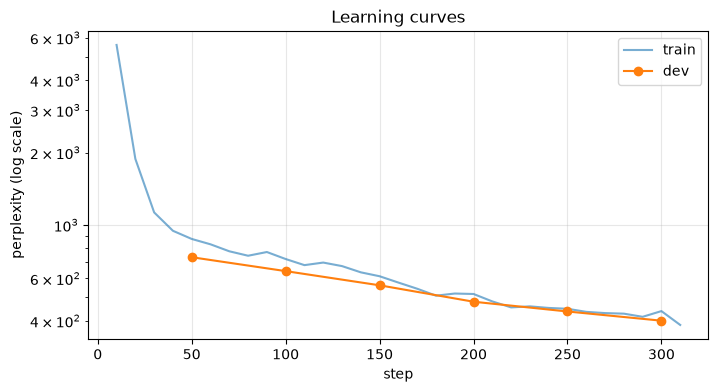

In [14]:
plt.figure(figsize=(8, 4))
plt.plot(history["step"], history["train_ppl"], label="train", alpha=0.6)
plt.plot(history["dev_step"], history["dev_ppl"], "o-", label="dev")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("perplexity (log scale)"); plt.legend(); plt.grid(alpha=.3)
plt.title("Learning curves"); plt.show()

## 9. Decoding: greedy & beam search

At test time there's no gold target, so the model feeds its **own** predictions back in. We want

$$
\hat{\mathbf{y}} = \arg\max_{\mathbf{y}} \log P(\mathbf{y}\mid\mathbf{x}) = \arg\max_{\mathbf{y}} \sum_t \log P(y_t\mid y_{<t},\mathbf{x})
$$

but searching all $V^T$ sentences is impossible.

**Greedy:** take $\arg\max$ at each step. Fast, but an early mistake can't be undone.

**Beam search:** keep the $k$ best partial translations ("hypotheses") by cumulative log-prob. At each step, expand each with every word, keep the top $k$ of the $k\times V$ candidates; a hypothesis that emits `</s>` is finished. Stop when $k$ are finished or the max length is reached.

```
k = 2         t=1            t=2                  t=3
<s> ──┬── the (-0.4) ──┬── the culprit (-1.1) ──┬── … culprit was (-1.5)
      │                └── the thieves (-1.9)   └── … culprit is  (-2.6)  ✗ pruned
      └── a   (-1.2) ──┬── a thief     (-2.0)   ✗ pruned (not in top-2)
                       └── …
```

Raw log-prob sums favour **short** outputs (every extra token adds a negative term). A common fix is **length normalisation**, score $= \frac{\log P}{|\mathbf{y}|^{\alpha}}$. The original uses $\alpha=0$ (none); try $\alpha\approx0.6$–$1$.

In [16]:
@torch.no_grad()
def greedy_decode(model, src, src_lens, max_len=70):
    # Batched greedy decoding. Returns token-id lists and attention maps (b, L, m).
    model.eval()
    enc_h, state = model.encode(src, src_lens)
    mask, enc_h_proj = src == PAD, model.att_proj(enc_h)
    b = src.size(0)
    y = torch.full((b,), BOS, device=src.device)
    o_prev = enc_h.new_zeros(b, model.hidden_size)
    outs, attns, done = [], [], torch.zeros(b, dtype=torch.bool, device=src.device)
    for _ in range(max_len):
        state, o_prev, alpha = model.step(torch.cat([model.tgt_embed(y), o_prev], -1), state, enc_h, enc_h_proj, mask)
        y = model.vocab_proj(o_prev).argmax(-1)
        outs.append(y); attns.append(alpha)
        done |= y == EOS
        if done.all(): break
    seqs = [s[:s.index(EOS)] if EOS in s else s for s in torch.stack(outs, 1).tolist()]
    return seqs, torch.stack(attns, 1)

@torch.no_grad()
def beam_search(model, src_ids, beam_size=5, max_len=70, alpha=0.0):
    # Beam search for one sentence. Returns the best list of target ids (without <s>/</s>).
    model.eval()
    src_ids = src_ids or [UNK]
    src = torch.tensor([src_ids], device=device)
    enc_h, state = model.encode(src, torch.tensor([len(src_ids)]))
    enc_h_proj = model.att_proj(enc_h)
    V = model.vocab_proj.out_features

    hyps, scores = [[BOS]], torch.zeros(1, device=device)          # live hypotheses + their log-probs
    o_prev = torch.zeros(1, model.hidden_size, device=device)
    finished = []                                                   # (tokens, log-prob)
    for _ in range(max_len):
        k = len(hyps)
        y = torch.tensor([h[-1] for h in hyps], device=device)
        state, o_t, _ = model.step(torch.cat([model.tgt_embed(y), o_prev], -1), state,
                                   enc_h.expand(k, -1, -1), enc_h_proj.expand(k, -1, -1))
        log_p = F.log_softmax(model.vocab_proj(o_t), dim=-1)        # (k, V)
        cand = (scores.unsqueeze(1) + log_p).view(-1)               # (k*V,)
        top_scores, top_pos = cand.topk(beam_size - len(finished))

        new_hyps, keep, new_scores = [], [], []
        for pos, s in zip(top_pos.tolist(), top_scores.tolist()):
            prev, word = divmod(pos, V)                             # which hypothesis, which word
            if word == EOS:
                finished.append((hyps[prev][1:], s))
            else:
                new_hyps.append(hyps[prev] + [word]); keep.append(prev); new_scores.append(s)
        if len(finished) >= beam_size or not new_hyps:
            break
        keep = torch.tensor(keep, device=device)
        state, o_prev = (state[0][keep], state[1][keep]), o_t[keep]
        hyps, scores = new_hyps, torch.tensor(new_scores, device=device)

    if not finished:
        finished = [(h[1:], s) for h, s in zip(hyps, scores.tolist())]
    best_tokens, _ = max(finished, key=lambda f: f[1] / max(len(f[0]), 1) ** alpha)
    return best_tokens

In [17]:
for i in range(5):
    zh, en = raw["dev"][0][i], raw["dev"][1][i]
    ids = sp_src.encode(zh)
    g, _ = greedy_decode(model, torch.tensor([ids], device=device), torch.tensor([len(ids)]))
    b = beam_search(model, ids, cfg.beam_size, cfg.max_decode_len)
    print(f"ZH    : {zh}\nREF   : {en}\nGREEDY: {sp_tgt.decode(g[0])}\nBEAM  : {sp_tgt.decode(b)}\n")

ZH    : 应注意到会议决定遵守程序应与争端解决程序和机制分开并且不对后者产生影响。
REF   : it is important to note that it was decided that the compliance procedure shall be separate from, and without prejudice to, the dispute settlement procedures and mechanisms.
GREEDY: the united of the united of the united of the united of the united of the united of the united of the united of the united.
BEAM  : in the government of the government of the government of the government of the government of the government of the government of the government.

ZH    : *凡在香港经营生产光碟的人士必须向海关关长领取牌照。
REF   : * all manufacturers of optical discs in hong kong will be required to obtain a licence from the commissioner of customs and excise.
GREEDY: the united of the united of the united of the united of the united of the united of the united.
BEAM  : it, the government of the government of the government of the government of the government.

ZH    : 这确实是最为重要的,因为除非实现这点,否则留给子孙后代的就只是混乱与破坏。
REF   : this is surely of the utmost importance, because unle

## 10. Evaluation: corpus BLEU (Q1h) and attention heatmaps

We score test-set translations with **sacreBLEU**, the standard implementation (fixed tokenisation, so scores are comparable across papers). The handout's target is **corpus BLEU > 18** (the reference solution got about 20.3). Note `sp_tgt.decode` turns subword pieces back into normal text before scoring. Scoring raw subwords would inflate BLEU.

Corpus BLEU pools n-gram counts over **all** sentences before taking the ratios. It is not the average of sentence BLEUs (see §11 for the formula).

In [18]:
test_zh, test_en = raw["test"]
if cfg.debug:                       # beam search on CPU is slow; score a slice (BLEU will be low in debug anyway)
    test_zh, test_en = test_zh[:100], test_en[:100]
hyps = [sp_tgt.decode(beam_search(model, ids, cfg.beam_size, cfg.max_decode_len))
        for ids in tqdm(sp_src.encode(test_zh), desc="beam search")]
bleu = sacrebleu.corpus_bleu(hyps, [test_en])
print(bleu)            # BLEU = score  1-gram/2-gram/3-gram/4-gram precisions  (BP, ratio, lengths)

Path("outputs").mkdir(exist_ok=True)
Path("outputs/test_outputs.txt").write_text("\n".join(hyps), encoding="utf8")

beam search: 100%|██████████| 100/100 [00:02<00:00, 41.27it/s]

BLEU = 0.48 22.4/2.4/0.1/0.0 (BP = 0.897 ratio = 0.902 hyp_len = 2034 ref_len = 2256)


11065

**Attention heatmap.** Each row is one generated English piece; each column is one Chinese source piece. Bright cells show where the decoder "looked". For a good model you should see a rough diagonal (word order is similar), with jumps where Chinese and English order differ.

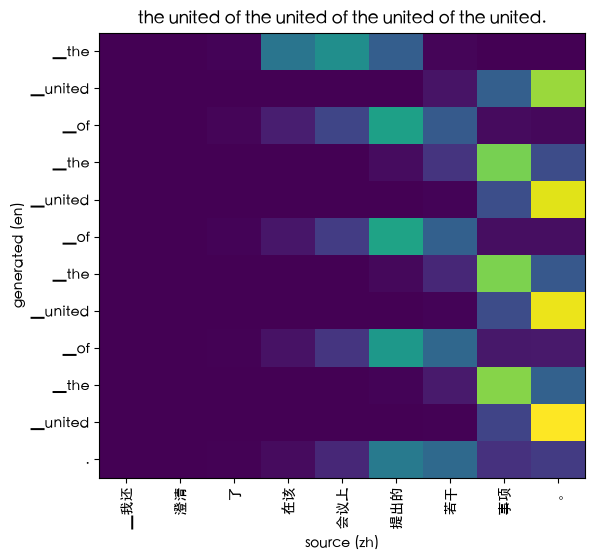

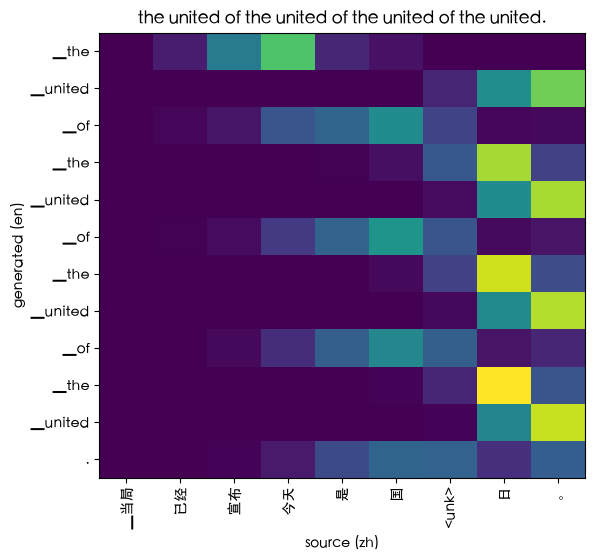

In [19]:
from matplotlib import font_manager
def use_cjk_font():
    for name in ["Noto Sans CJK SC", "Noto Sans CJK JP", "Noto Serif CJK SC", "SimHei", "PingFang SC",
                 "Heiti SC", "Microsoft YaHei", "WenQuanYi Zen Hei", "Arial Unicode MS"]:
        if any(name == f.name for f in font_manager.fontManager.ttflist):
            plt.rcParams["font.family"] = name; return True
    print("No CJK font found → Chinese labels will show as boxes. "
          "On Colab: !apt-get -qq install fonts-noto-cjk, then restart the runtime.")
    return False
use_cjk_font()

def plot_attention(zh):
    ids = sp_src.encode(zh)
    out, attn = greedy_decode(model, torch.tensor([ids], device=device), torch.tensor([len(ids)]))
    L = len(out[0])
    attn = attn[0, :L].cpu().numpy()
    fig, ax = plt.subplots(figsize=(0.45 * len(ids) + 2, 0.35 * L + 1.5))
    ax.imshow(attn, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(ids)), [sp_src.id_to_piece(i) for i in ids], rotation=90)
    ax.set_yticks(range(L), [sp_tgt.id_to_piece(i) for i in out[0]])
    ax.set_xlabel("source (zh)"); ax.set_ylabel("generated (en)")
    ax.set_title(sp_tgt.decode(out[0])[:80]); plt.tight_layout(); plt.show()

plot_attention(raw["dev"][0][3])
plot_attention("当局已经宣布今天是国殇日。")     # one of the Q2b error examples

## 11. Written questions, answered

### Q1g — What do the masks do, and why are they needed?

**Effect:** before the softmax, every attention score $\mathbf{e}_{t,i}$ at a `<pad>` position is set to $-\infty$. Since $e^{-\infty}=0$, those positions get $\alpha_{t,i}=0$, and the remaining weights still sum to 1 over the *real* tokens only. So the context vector $\mathbf{a}_t$ is a weighted average of real encoder states only.

**Why:** padding exists only to make the batch rectangular. Without the mask, a short sentence would spread some attention onto meaningless pad states, and its translation would depend on how long the *other* sentences in the batch happen to be.

### Q1i — Attention variants

| | score $\mathbf{e}_{t,i}$ | advantage vs multiplicative | disadvantage vs multiplicative |
|---|---|---|---|
| **dot product** | $\mathbf{s}_t^\top\mathbf{h}_i$ | no parameters, fastest (one mat-mul) | needs $\mathbf{s}_t$ and $\mathbf{h}_i$ to have the **same dimension and live in the same space**; can't learn *which* dimensions should interact (here $2h \ne h$, so it wouldn't even fit) |
| multiplicative | $\mathbf{s}_t^\top\mathbf{W}\mathbf{h}_i$ | — | — |
| **additive** | $\mathbf{v}^\top\tanh(\mathbf{W}_1\mathbf{h}_i + \mathbf{W}_2\mathbf{s}_t)$ | more expressive (a small non-linear network), handles different sizes naturally | more parameters + an extra hyper-parameter (attention dim); slower, since it can't be done as one fused mat-mul |

(Transformers use **scaled** dot-product $\frac{\mathbf{q}^\top\mathbf{k}}{\sqrt{d}}$ on learned projections, which is essentially multiplicative attention with $\mathbf{W}=\mathbf{W}_Q^\top\mathbf{W}_K$.)

### Q2a — Why a 1D convolution after the embeddings?

Chinese is written without spaces, and each character is either a word or a morpheme. SentencePiece sometimes keeps a word as one piece and sometimes splits it (电 + 脑). A kernel-size-2 convolution gives every position a learned feature of **itself and its neighbour**, i.e. a bigram detector. It can learn that 电 next to 脑 means *computer*, not "electricity brain", before the BiLSTM even starts. It is cheap, parallel, and adds local, phrase-level information the LSTM would otherwise have to learn through its recurrence.

### Q2b — Error analysis

| # | source → reference vs model | error | likely cause | possible fix |
|---|---|---|---|---|
| i | 贼人其后被警方拘捕… → *the **culprits were*** vs *the **culprit was*** | number: singular instead of plural | Chinese nouns aren't marked for plural (贼人 can be one or many), so the model falls back to the more frequent singular | more data / bigger model; give the model wider (document-level) context, which is often the only clue |
| ii | 几乎已经没有地方容纳这些人,资源已经用尽 → *…no space to accommodate these people, and resources have run out* vs *the resources have been exhausted and **resources have been exhausted*** | repetition; the first clause is dropped | attention has no memory of what was already translated, so it attends to the same source span twice (*over-translation*) and skips another (*under-translation*) | **coverage** mechanism / coverage penalty; n-gram repetition blocking in beam search |
| iii | 当局已经宣布今天是国殇日 → *a **national mourning today*** vs ***today's day*** | rare compound mistranslated | 国殇日 is rare in training; the model only knows 日 = *day* and 今天 = *today* | more data containing the term, a terminology/glossary constraint, or a pretrained multilingual model |
| iv | 俗语有云:"唔做唔错" → *"**act not, err not**"* vs *"**it's not wrong**"* | idiom lost | it's **Cantonese** (唔 = Mandarin 不 "not"), which is rare in the mostly-Mandarin training data; idioms aren't literal | add Cantonese / idiom data (domain adaptation), or use a model pretrained on more varied Chinese |

### Q2c — BLEU

For candidate $\mathbf{c}$ and references $\mathbf{r}_1..\mathbf{r}_k$:

$$
p_n = \frac{\sum_{\text{ngram}\in\mathbf{c}} \min\big(\max_i \text{Count}_{\mathbf{r}_i}(\text{ngram}),\ \text{Count}_{\mathbf{c}}(\text{ngram})\big)}{\sum_{\text{ngram}\in\mathbf{c}}\text{Count}_{\mathbf{c}}(\text{ngram})}
\qquad\text{(clipped n-gram precision)}
$$

$$
BP = \begin{cases}1 & len(c)\ge len(r)\\ e^{\,1-len(r)/len(c)} & \text{otherwise}\end{cases}
\qquad
\text{BLEU} = BP\cdot\exp\Big(\sum_{n}\lambda_n\log p_n\Big)
$$

- **Clipping** stops "the the the the" from scoring perfect unigram precision.
- **Brevity penalty** stops very short candidates from scoring well (precision alone rewards saying little). $len(r)$ is the reference length closest to $len(c)$; on ties, take the shorter.
- With $\lambda=(\tfrac12,\tfrac12)$ it's the geometric mean of $p_1, p_2$.

Rather than counting by hand, here's the formula in code, checked against `nltk`:

In [ ]:
from collections import Counter
from nltk.translate.bleu_score import sentence_bleu

def ngrams(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

def modified_precision(c, refs, n):
    c_counts = ngrams(c, n)
    max_ref = Counter()
    for r in refs:
        for g, k in ngrams(r, n).items():
            max_ref[g] = max(max_ref[g], k)
    return sum(min(k, max_ref[g]) for g, k in c_counts.items()) / max(sum(c_counts.values()), 1)

def brevity_penalty(c, refs):
    lc = len(c)
    lr = len(min(refs, key=lambda r: (abs(len(r) - lc), len(r))))   # closest length, ties → shorter
    return (1.0 if lc >= lr else math.exp(1 - lr / lc)), lr

def bleu_explained(c, refs, weights=(0.5, 0.5)):
    p = [modified_precision(c, refs, n + 1) for n in range(len(weights))]
    bp, lr = brevity_penalty(c, refs)
    score = 0.0 if min(p) == 0 else bp * math.exp(sum(w * math.log(pn) for w, pn in zip(weights, p)))
    return dict(p1=round(p[0], 3), p2=round(p[1], 3), len_c=len(c), len_r=lr, BP=round(bp, 3), BLEU=round(score, 3))

r1 = "resources have to be sufficient and they have to be predictable".split()
r2 = "adequate and predictable resources are required".split()
c1 = "there is a need for adequate and predictable resources".split()
c2 = "resources be sufficient and predictable to".split()

for title, refs in [("(i) references r1 + r2", [r1, r2]), ("(ii) reference r2 only", [r2])]:
    print(title)
    for name, c in [("c1", c1), ("c2", c2)]:
        res = bleu_explained(c, refs)
        assert abs(res["BLEU"] - sentence_bleu(refs, c, weights=(0.5, 0.5))) < 1e-3   # agrees with nltk
        print(f"  {name}: {res}")

**(i) With both references:** $c_1$: $p_1=4/9$, $p_2=3/8$, $len(c)=9$, $len(r)=11$, $BP=e^{-2/9}$ → **0.327**. $c_2$: $p_1=6/6$, $p_2=3/5$, $len(c)=len(r)=6$, $BP=1$ → **0.775**.
BLEU prefers $c_2$, but $c_2$ ("resources be sufficient and predictable to") is ungrammatical. $c_1$ is the better translation. $c_2$ wins only because it copies words from $r_1$.

**(ii) With only $r_2$:** $c_1$ → **0.408** ($BP=1$, since $9 > 6$); $c_2$ → **0.316** ($p_1=1/2$, $p_2=1/5$). Now $c_1$ wins, which matches human judgement. The ranking flipped just by changing the references.

**(iii) Why is a single reference problematic?** A sentence has many valid translations (synonyms, word order, phrasing). BLEU only rewards n-grams that appear in *some* reference. With several references, a good translation has many chances to match; with one, a perfectly fine translation that happens to use different words (*adequate* vs *sufficient*) is penalised. Part (ii) shows this directly: the scores and the ranking changed when $r_1$ disappeared. Over a large test set the noise averages out somewhat, but single-reference sentence-level BLEU is unreliable.

**(iv) BLEU vs human evaluation**

| advantages | disadvantages |
|---|---|
| fast, free, automatic: re-run after every experiment | only surface n-gram overlap: no credit for synonyms or paraphrases, and no notion of meaning |
| deterministic and reproducible (sacreBLEU), language-independent | all words weigh the same ("not" ≈ "the"), so a translation with flipped meaning can score high; weak at sentence level and on fluency/grammar |

(Modern practice adds learned metrics like **COMET** or **BLEURT**, which correlate better with humans, plus human evaluation for final claims.)

## 12. Optional: how does a modern pretrained model compare?

LSTM seq2seq with attention (2014–2016) was replaced by the **Transformer** (2017), which drops recurrence entirely and uses self-attention in both encoder and decoder. Here's a pretrained Transformer MT model (MarianMT, `Helsinki-NLP/opus-mt-zh-en`) on the same test sentences. Expect it to score higher: it was trained on far more data. Set `RUN_PRETRAINED = True` to try it (downloads ~300 MB).

In [ ]:
RUN_PRETRAINED = False
if RUN_PRETRAINED:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers"], check=True)
    from transformers import pipeline
    translator = pipeline("translation", model="Helsinki-NLP/opus-mt-zh-en", device=0 if device.type == "cuda" else -1)
    n = 200
    marian = [o["translation_text"].lower() for o in translator(test_zh[:n], batch_size=32)]
    print("ours   :", sacrebleu.corpus_bleu(hyps[:n], [test_en[:n]]).score)
    print("marian :", sacrebleu.corpus_bleu(marian, [test_en[:n]]).score)

## 13. Cheat sheet

- **NMT** models $P(\mathbf{y}\mid\mathbf{x})=\prod_t P(y_t\mid y_{<t},\mathbf{x})$ end-to-end with one network.
- **Subword tokenization** (SentencePiece/BPE/Unigram) handles languages without spaces and avoids `<unk>`.
- **Padding + masking:** pad to make batches rectangular, then (a) **pack** so the LSTM ignores pads and (b) set attention scores to $-\infty$ so attention ignores pads.
- **BiLSTM encoder:** every source position gets left *and* right context ($2h$ dims). The decoder starts from a projection of $[\overleftarrow{\mathbf{h}}_1;\overrightarrow{\mathbf{h}}_m]$.
- **Attention** = score → softmax → weighted sum. Multiplicative: $\mathbf{h}_t^\top\mathbf{W}\mathbf{h}^{enc}_i$. It removes the single-vector bottleneck and gives interpretable alignments.
- **Input feeding:** feed $\mathbf{o}_{t-1}$ into the next decoder step.
- **Teacher forcing** in training (gold previous token); **beam search** at inference (own predictions, keep top-$k$).
- **Loss** = token-level cross-entropy; **perplexity** = $e^{\text{avg loss}}$.
- **Training hygiene:** sanity-check initial loss ≈ $\ln V$, overfit one batch, clip gradients, select on dev, decay LR on plateau.
- **BLEU** = brevity penalty × geometric mean of clipped n-gram precisions. Use sacreBLEU, detokenize first, and remember it's a rough proxy that is sensitive to the references.